# 01 California
Este dataset es un recopilatorio de un censo de California de 1990, cada fila representa una zona y cada columna los diferentes datos de las zonas, tales como:   Ubicación geográfica; total de habitaciones y dormitorios;  cantidad de hogares; población de la zona; mediana de ingresos, valor y edad de las casas de la zona; y proximidad al océano.  Buscamos responder a la pregunta ¿Qué hace caras a las casas en California? Esta pregunta se responde con los datos que encontremos en cada zona.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Exploración

In [2]:
df = pd.read_csv("housing.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
df.shape

(20640, 10)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


* El dataset tiene 20640 filas y 10 columnas, y cada fila representa una zona o bloque de casas.
* De las 10 columnas, 9 son numéricas y 1 es categórica, que es `ocean_proximity`.
* La única columna con valores faltantes es `total_bedrooms`, con 207 nulos.

## 2. Limpieza y preprocesamiento

Analizamos que tienen en comun las filas nulas en `total_bedrooms`.

In [5]:
df_nulos = df[df['total_bedrooms'].isnull()]
df_nulos

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
290,-122.16,37.77,47.0,1256.0,NaN,570.0,218.0,4.3750,161900.0,NEAR BAY
341,-122.17,37.75,38.0,992.0,NaN,732.0,259.0,1.6196,85100.0,NEAR BAY
538,-122.28,37.78,29.0,5154.0,NaN,3741.0,1273.0,2.5762,173400.0,NEAR BAY
563,-122.24,37.75,45.0,891.0,NaN,384.0,146.0,4.9489,247100.0,NEAR BAY
696,-122.10,37.69,41.0,746.0,NaN,387.0,161.0,3.9063,178400.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20267,-119.19,34.20,18.0,3620.0,NaN,3171.0,779.0,3.3409,220500.0,NEAR OCEAN
20268,-119.18,34.19,19.0,2393.0,NaN,1938.0,762.0,1.6953,167400.0,NEAR OCEAN
20372,-118.88,34.17,15.0,4260.0,NaN,1701.0,669.0,5.1033,410700.0,<1H OCEAN
20460,-118.75,34.29,17.0,5512.0,NaN,2734.0,814.0,6.6073,258100.0,<1H OCEAN


In [6]:
df_nulos['ocean_proximity'].value_counts(normalize=True)

ocean_proximity
<1H OCEAN     0.492754
INLAND        0.265700
NEAR OCEAN    0.144928
NEAR BAY      0.096618
Name: proportion, dtype: float64

In [7]:
df['ocean_proximity'].value_counts(normalize=True)

ocean_proximity
<1H OCEAN     0.442636
INLAND        0.317393
NEAR OCEAN    0.128779
NEAR BAY      0.110950
ISLAND        0.000242
Name: proportion, dtype: float64

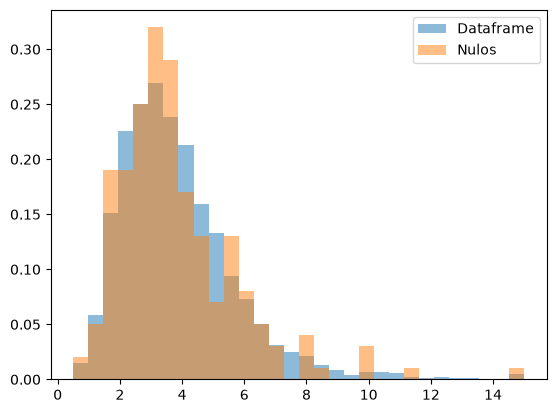

In [8]:
bordes = np.histogram_bin_edges(df['median_income'],bins=30)
plt.hist(df['median_income'],
        bins=bordes,
        density=True,
        alpha=0.5,
        label= "Dataframe")

plt.hist(df_nulos['median_income'],
         bins=bordes,
         density=True,
         alpha=0.5,
         label="Nulos")

plt.legend()
plt.show()

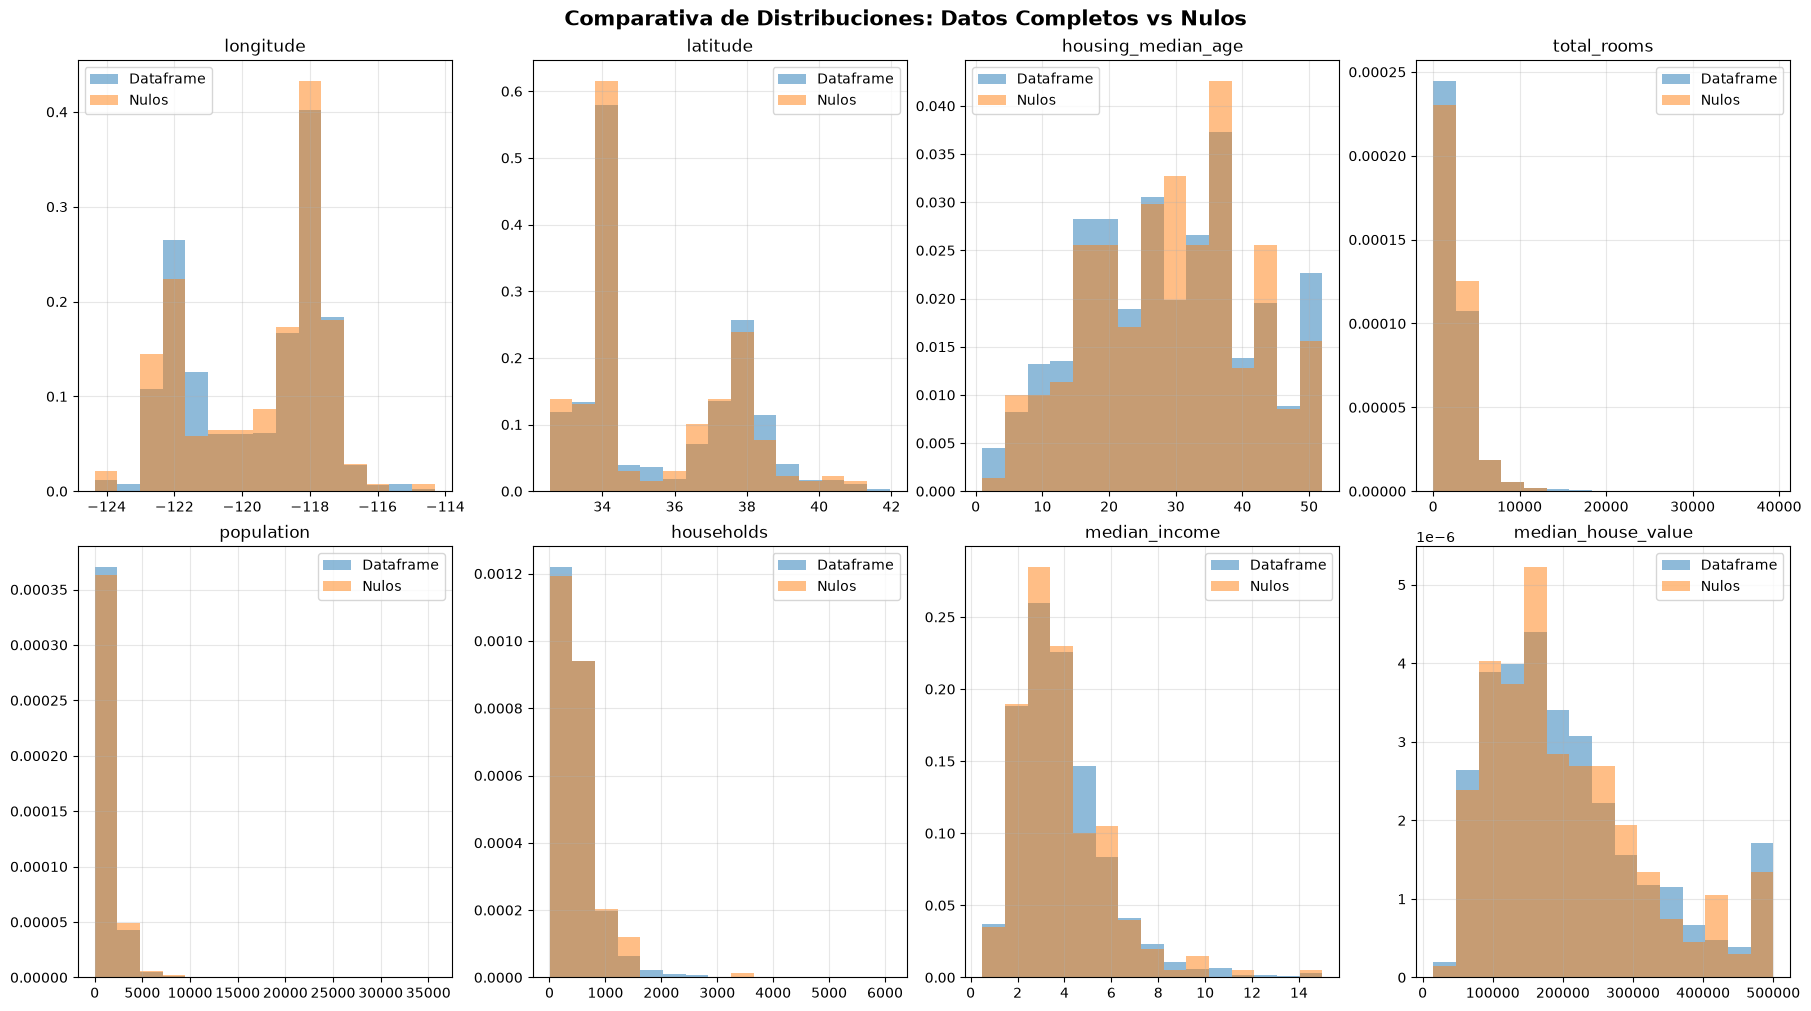

In [9]:
columnas = ['longitude','latitude','housing_median_age','total_rooms',
            'population','households', 'median_income' ,'median_house_value']


# fig, axs = plt.subplots(2, 4, figsize=(18, 10), layout='constrained')
# axs_planos = axs.flatten()  # Convierte la matriz en una lista simple de 8 espacios

# for i, col in enumerate(columnas):
#     ax = axs_planos[i]
    
#     ax.hist(df[col], density=True, alpha=0.5, label='Completos')
#     ax.hist(df_nulos[col], density=True, alpha=0.5, label='Nulos')
#     ax.set_title(col)


fig, axs = plt.subplots(2,4, figsize=(18,10), layout='constrained')

for i, col in enumerate(columnas):
        fila = i//4
        columna = i%4

        ax = axs[fila,columna]

        bordes = np.histogram_bin_edges(df[col],bins=15)

        ax.hist(df[col],
                bins=bordes,
                density=True,
                alpha=0.5,
                label= "Dataframe")

        ax.hist(df_nulos[col],
                bins=bordes,
                density=True,
                alpha=0.5,
                label="Nulos")

        ax.set_title(col, fontsize=12)
        ax.legend()
        ax.grid(True, alpha=0.3)

fig.suptitle("Comparativa de Distribuciones: Datos Completos vs Nulos", fontsize=15, weight='bold')
plt.show()

La evidencia **muestra** que los nulos de `total_bedrooms` no se concentran en ninguna zona ni tipo de zona que podamos detectar con estas variables. Eso no prueba que sean “al azar”, pero sí que no hay un sesgo visible. Al alrededor del 1% de las filas del dataset, en este caso se decide eliminar las filas con `total_bedrooms` nulos.

In [10]:
df_limpio = df.dropna(subset=['total_bedrooms'])

In [11]:
df_limpio.shape

(20433, 10)

In [12]:
df_limpio.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [13]:
df_limpio.duplicated().sum()

np.int64(0)

No se encontraron filas duplicadas.

In [14]:
df_limpio.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000
mean,-119.570689,35.633221,28.633094,2636.504233,537.870553,1424.946949,499.433465,3.871162,206864.413155
std,2.003578,2.136348,12.591805,2185.269567,421.385070,1133.208490,382.299226,1.899291,115435.667099
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1450.000000,296.000000,787.000000,280.000000,2.563700,119500.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.536500,179700.000000
75%,-118.010000,37.720000,37.000000,3143.000000,647.000000,1722.000000,604.000000,4.744000,264700.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


Se ven valores muy bajos en los minimos de total_rooms, total_bedrooms y population se asume que puede tratarse de una zona muy apartada, probablemente rural, no hay forma de comprobarlo fehacientemente. También se aprecia que los valores máximos están muy por encima del 75%. No aparece ningún valor imposible, no hay negativos.

In [15]:
calculo = (df_limpio["median_house_value"] == 500001).sum()
calculo

np.int64(958)

In [16]:
(calculo / df_limpio.shape[0])*100

np.float64(4.6884941026770415)

### ~4.7% de zonas que son afectadas por tope de media de precio.

In [17]:
df_tope_value = df_limpio[df_limpio['median_house_value'] == 500001]

print(df_tope_value['ocean_proximity'].value_counts(normalize=True))
df_limpio['ocean_proximity'].value_counts(normalize=True)

ocean_proximity
<1H OCEAN     0.552192
NEAR OCEAN    0.218163
NEAR BAY      0.201461
INLAND        0.028184
Name: proportion, dtype: float64


ocean_proximity
<1H OCEAN     0.442128
INLAND        0.317917
NEAR OCEAN    0.128615
NEAR BAY      0.111095
ISLAND        0.000245
Name: proportion, dtype: float64

958 zonas (4,7%) figuran con median_house_value = 500.001, que parece ser un tope del dataset.  
Esas zonas se concentran cerca del mar (solo 2,8% son INLAND, contra 31,8% en el total).  
Por el tope, entre estas zonas no se puede saber cuáles son más caras que otras.  

In [18]:
df_sin_tope = df_limpio[df_limpio['median_house_value'] != 500001]
df_sin_tope.shape

(19475, 10)

In [19]:
print(f'df_limpio {df_limpio["median_house_value"].mean()}')
print(f'df_sin_tope {df_sin_tope["median_house_value"].mean()}')

df_limpio 206864.41315519012
df_sin_tope 192444.6519127086


El promedio baja significativamente, `14400`, de 206.864 `df_limpio` a 192.445 `df_sin_tope`, porque las zonas con el valor tope (500001) son 958, una cantidad y valor que no son despreciables.

## 3. Análisis simple

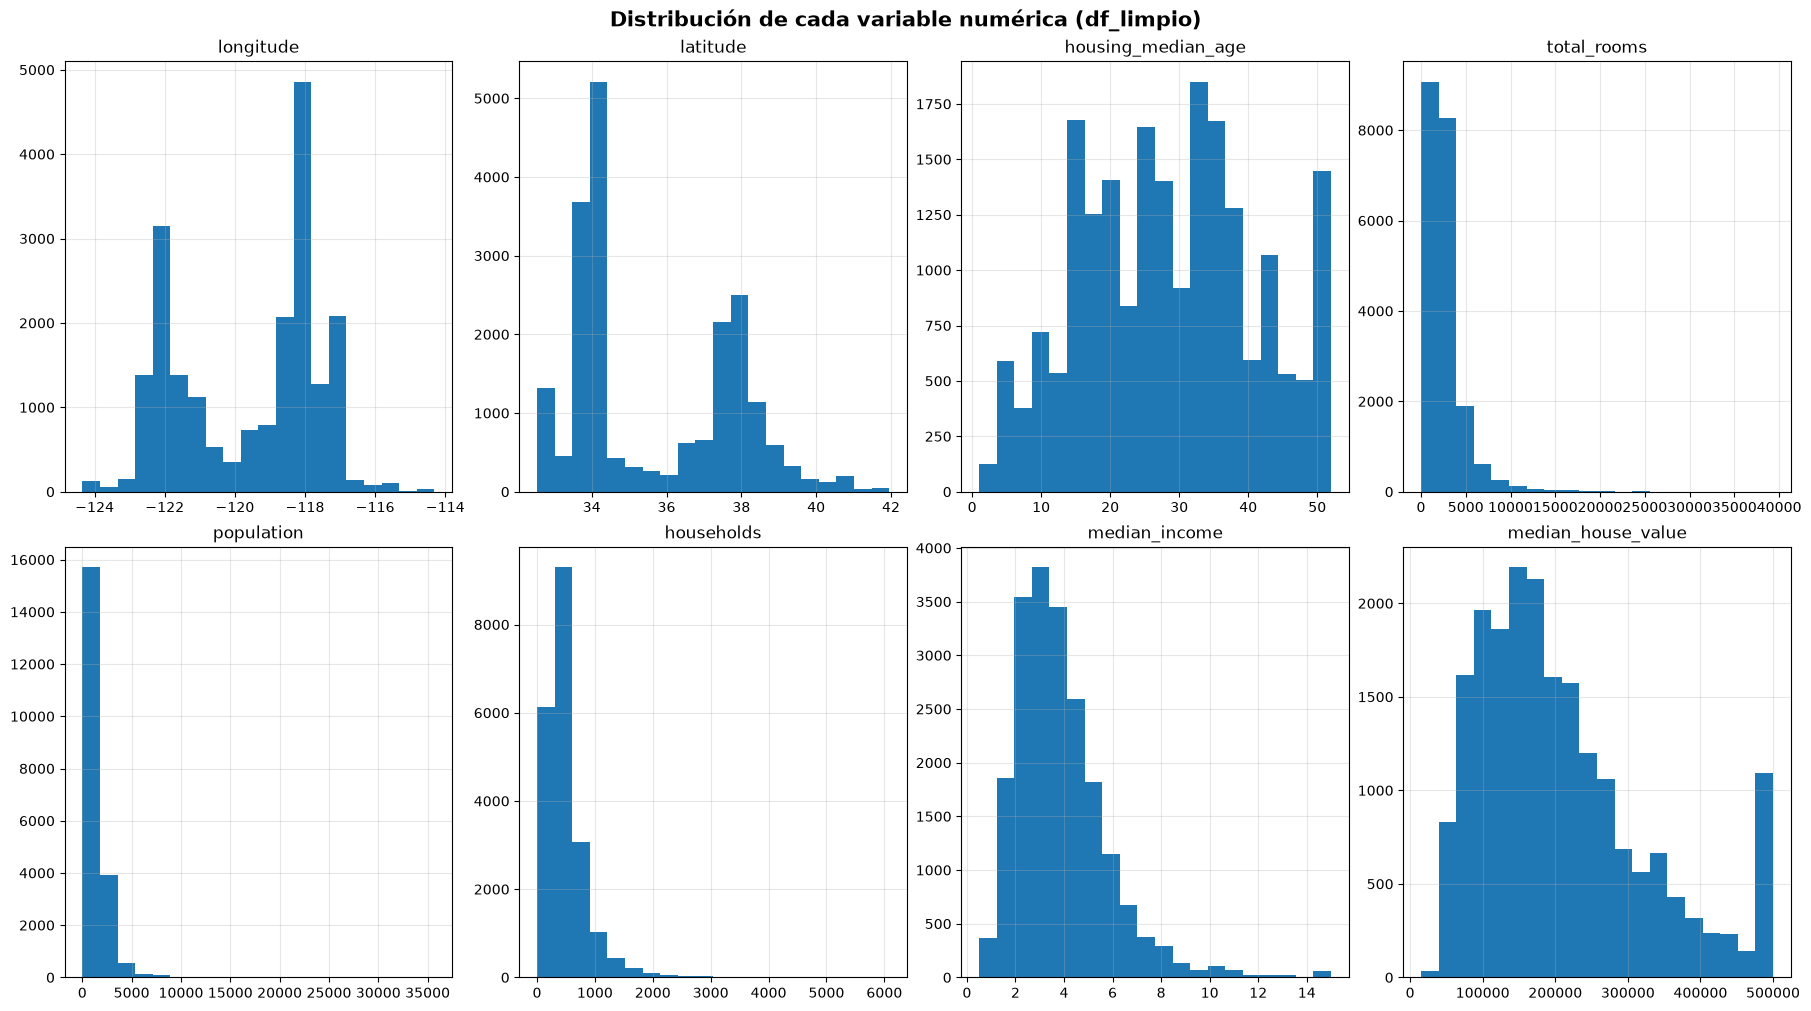

In [20]:
columnas = ['longitude','latitude','housing_median_age','total_rooms',
            'population','households', 'median_income' ,'median_house_value']


fig, axs = plt.subplots(2,4, figsize=(18,10), layout='constrained')

for i, col in enumerate(columnas):
        fila = i//4
        columna = i%4

        ax = axs[fila,columna]

        ax.hist(df_limpio[col], bins=20)

        ax.set_title(col, fontsize=12)
        ax.grid(True, alpha=0.3)

fig.suptitle("Distribución de cada variable numérica (df_limpio)", fontsize=15, weight='bold')
plt.show()

- `population`, `households`, `median_income`, `median_house_value` y `total_rooms` se ven claramente asimétricas a la derecha.   
- `median_house_value` tiene un tope muy marcado a la derecha.
- `median_income` y `housing_median_age` aparentan también tener un tope a la derecha.
- `longitude` y `latitude` son bimodales: tienen un pico grande y otro más chico que parecen coincidir con las ubicaciones de zonas urbanas muy pobladas. Se aprecia mejor más adelante con el mapa.

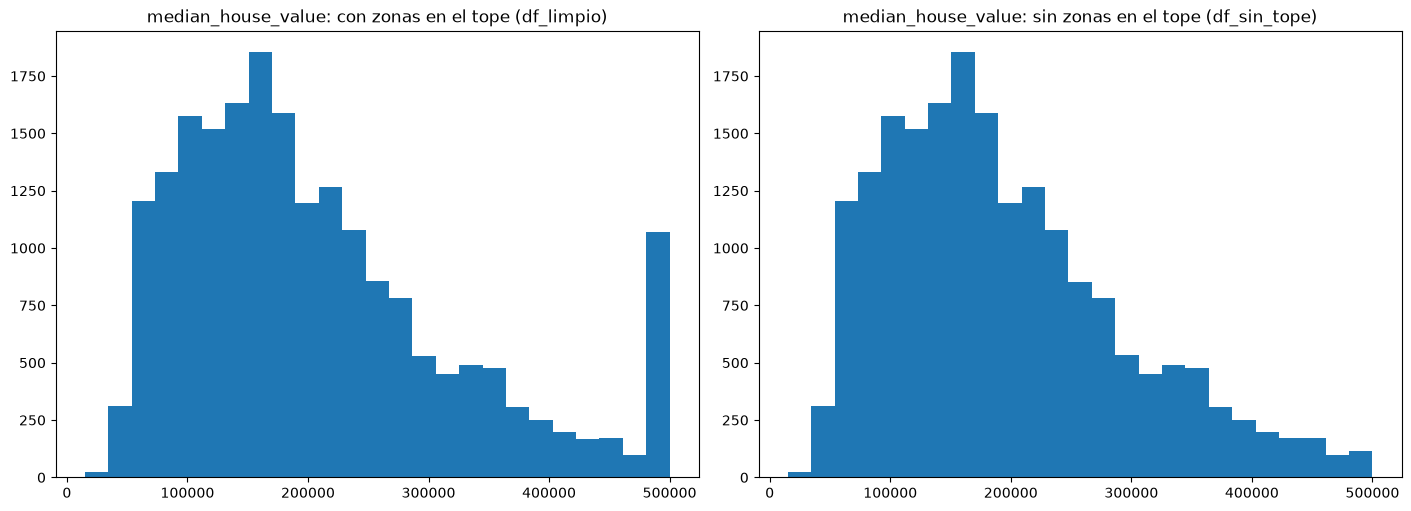

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')

axs[0].hist(df_limpio['median_house_value'], bins=25)
axs[0].set_title('median_house_value: con zonas en el tope (df_limpio)')

axs[1].hist(df_sin_tope['median_house_value'], bins=25)
axs[1].set_title('median_house_value: sin zonas en el tope (df_sin_tope)')

plt.show()

La forma general no cambia desde `df_limpio` a `df_sin_tope`.   
La diferencia está en el extremo derecho: incluyendo el tope hay un pico de más de 1.000 zonas, de las cuales 958 valen 500.001, y sin el tope ese pico desaparece.   
La barra que queda al final del gráfico de sin tope son las zonas con valores cercanos o iguales a 500.000.   
Usar `df_sin_tope` muestra mejor la forma de los precios por debajo de los 500.000, pero deja afuera a las zonas más caras, así que el gráfico queda recortado por arriba.

In [22]:
conteo = df_limpio['ocean_proximity'].value_counts()
conteo

ocean_proximity
<1H OCEAN     9034
INLAND        6496
NEAR OCEAN    2628
NEAR BAY      2270
ISLAND           5
Name: count, dtype: int64

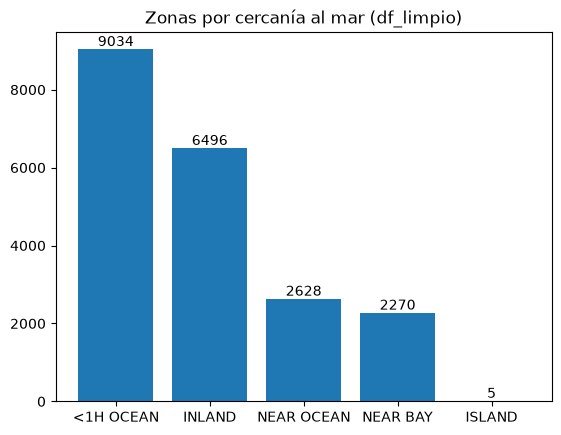

In [23]:
barras = plt.bar(conteo.index, conteo.values)
plt.bar_label(barras)
plt.title('Zonas por cercanía al mar (df_limpio)')
plt.show()

La mayoría de las zonas están en `<1H OCEAN` (9.034) o en `INLAND` (6.496).   
Siguen `NEAR OCEAN` (2.628) y `NEAR BAY` (2.270). `ISLAND` tiene solo 5 zonas y cualquier conclusión sobre esa categoría sería poco firme.

In [24]:
print("df limpio ",df_limpio.groupby('ocean_proximity')['median_house_value'].mean())
print("df sin tope ",df_sin_tope.groupby('ocean_proximity')['median_house_value'].mean())

df limpio  ocean_proximity
<1H OCEAN     240267.990812
INLAND        124896.863147
ISLAND        380440.000000
NEAR BAY      259279.292070
NEAR OCEAN    249042.355023
Name: median_house_value, dtype: float64
df sin tope  ocean_proximity
<1H OCEAN     224112.933568
INLAND        123331.271603
ISLAND        380440.000000
NEAR BAY      236910.832932
NEAR OCEAN    227359.694088
Name: median_house_value, dtype: float64


In [25]:
((df_tope_value['ocean_proximity'].value_counts() / df_limpio['ocean_proximity'].value_counts()) * 100)

ocean_proximity
<1H OCEAN     5.855656
INLAND        0.415640
ISLAND             NaN
NEAR BAY      8.502203
NEAR OCEAN    7.952816
Name: count, dtype: float64

`INLAND` tiene el promedio de precio más bajo (124896), casi la mitad que las categorías cercanas al mar, con o sin las zonas del tope. Al sacar esas zonas, el promedio baja ~22.000 en `NEAR BAY`, ~21.700 en `NEAR OCEAN` y ~16.200 en `<1H OCEAN`, mientras que en `INLAND` apenas ~1.600.

La razón es cuánto pesa el tope dentro de cada categoría: afecta al 8,5% de las zonas de `NEAR BAY`, al 8,0% de `NEAR OCEAN`, al 5,9% de `<1H OCEAN` y a solo el 0,4% de `INLAND`.

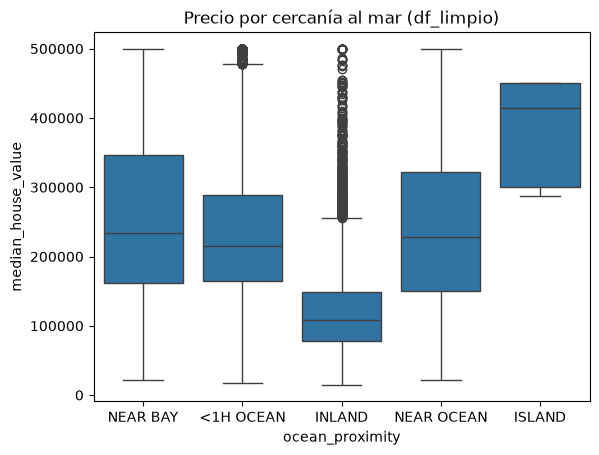

In [26]:
sns.boxplot(data=df_limpio, x='ocean_proximity', y='median_house_value')
plt.title('Precio por cercanía al mar (df_limpio)')
plt.show()

In [27]:
inland = df_limpio[df_limpio['ocean_proximity'] == 'INLAND']
(inland['median_house_value'] > 255000).sum()

np.int64(333)

In [28]:
(inland['median_house_value'] == 500001).sum()

np.int64(27)

In [29]:
df_limpio.groupby('ocean_proximity')['median_house_value'].median()

ocean_proximity
<1H OCEAN     215000.0
INLAND        108700.0
ISLAND        414700.0
NEAR BAY      233800.0
NEAR OCEAN    228750.0
Name: median_house_value, dtype: float64

`INLAND` es la categoría con la mediana de precios más bajos (108.700), y las categorías cercanas al mar tienen medianas parecidas entre sí, entre 215.000 y 233.800. `ISLAND` tiene la mediana más alta (414.700), pero son solo 5 zonas y no conviene sacar conclusiones de ahí.

`INLAND` tiene además muchos puntos por encima de los bigotes: unas 333 zonas superan los 255.000 (valor aproximado del límite), y de ellas solo 27 están en el tope de 500.001. Es decir que el interior tiene una cola de zonas caras para su categoría, y el tope es solo una parte pequeña de esa cola.

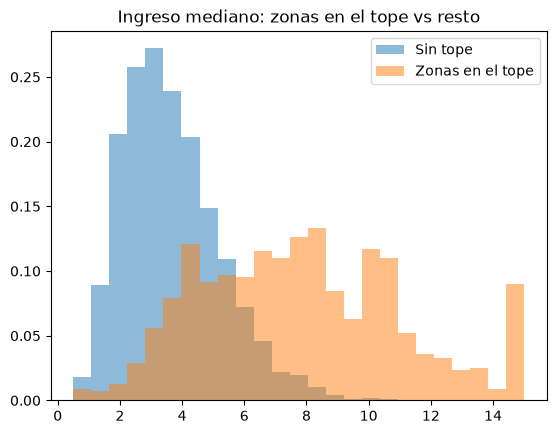

In [30]:
bordes = np.histogram_bin_edges(df_limpio['median_income'], bins=25)

plt.hist(df_sin_tope['median_income'], bins=bordes, density=True, alpha=0.5, label='Sin tope')
plt.hist(df_tope_value['median_income'], bins=bordes, density=True, alpha=0.5, label='Zonas en el tope')
plt.title('Ingreso mediano: zonas en el tope vs resto')
plt.legend()
plt.show()

In [31]:
(df_tope_value['median_income'] >= 15).sum()

np.int64(47)

In [32]:
df_ingreso_tope = df_limpio[df_limpio['median_income'] >= 15]

print(len(df_ingreso_tope))
(df_ingreso_tope['median_house_value'] == 500001).sum()

50


np.int64(47)

Las zonas con el precio en el tope tienen ingresos más altos que el resto: la mayoría está entre 5 y 11, contra 2 a 5 en el resto de las zonas, y su distribución es mucho más ancha.

Además, 47 de esas 958 zonas también tienen el ingreso en el tope (15 o más), cerca del 5%. Mirado desde el otro lado, hay 50 zonas con el ingreso en el tope y 47 de ellas (94%) también tienen el precio en el tope. Es decir que casi todas las zonas con ingreso máximo tienen precio máximo, pero casi todas las zonas con precio máximo no tienen ingreso máximo. Con solo 50 zonas, el 94% es una pista más que una regla.

## 4. Analisis complejo

In [33]:
matriz = df_limpio.corr(numeric_only=True)
matriz

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924616,-0.109357,0.045480,0.069608,0.100270,0.056513,-0.015550,-0.045398
latitude,-0.924616,1.000000,0.011899,-0.036667,-0.066983,-0.108997,-0.071774,-0.079626,-0.144638
housing_median_age,-0.109357,0.011899,1.000000,-0.360628,-0.320451,-0.295787,-0.302768,-0.118278,0.106432
total_rooms,0.045480,-0.036667,-0.360628,1.000000,0.930380,0.857281,0.918992,0.197882,0.133294
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.100270,-0.108997,-0.295787,0.857281,0.877747,1.000000,0.907186,0.005087,-0.025300
households,0.056513,-0.071774,-0.302768,0.918992,0.979728,0.907186,1.000000,0.013434,0.064894
median_income,-0.015550,-0.079626,-0.118278,0.197882,-0.007723,0.005087,0.013434,1.000000,0.688355
median_house_value,-0.045398,-0.144638,0.106432,0.133294,0.049686,-0.025300,0.064894,0.688355,1.000000


### Correlaciones

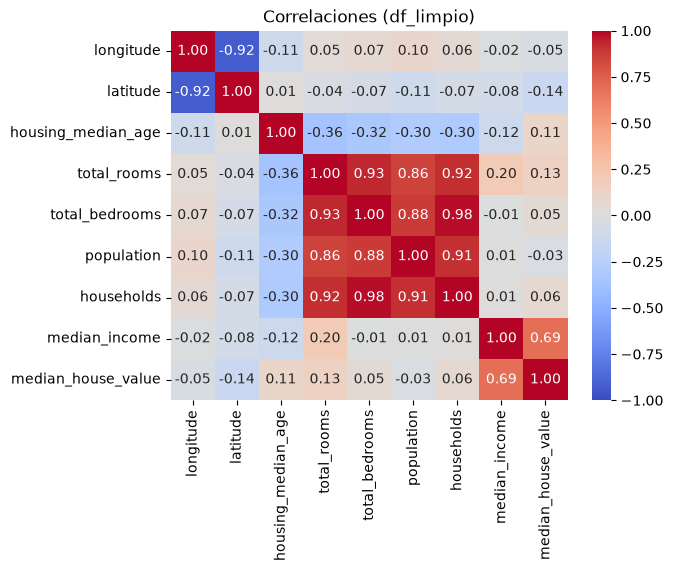

In [34]:
sns.heatmap(matriz, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlaciones (df_limpio)')
plt.show()

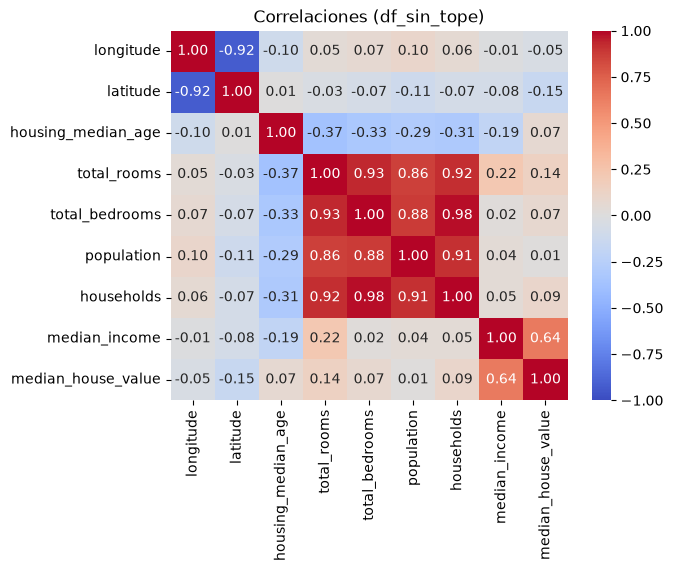

In [35]:
matriz_sin_tope = df_sin_tope.corr(numeric_only=True)

sns.heatmap(matriz_sin_tope, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlaciones (df_sin_tope)')
plt.show()

La variable que más se relaciona con el precio es `median_income`, con una correlación de 0,69. La más débil es `population` (-0,03). Las columnas de tamaño de la zona (`total_rooms`, `total_bedrooms`, `population` y `households`) están muy correlacionadas entre sí, hasta 0,98, pero no con el precio. `latitude` y `longitude` también están muy correlacionadas entre sí (-0,92) y casi nada con el precio, aunque eso no significa que la ubicación no importe: la correlación solo mide relaciones en línea recta.

La correlación entre ingresos y precio es de 0,69 con todas las zonas, y de 0,64 si se excluyen las 958 zonas con el precio topado.

### Ubicación y precio

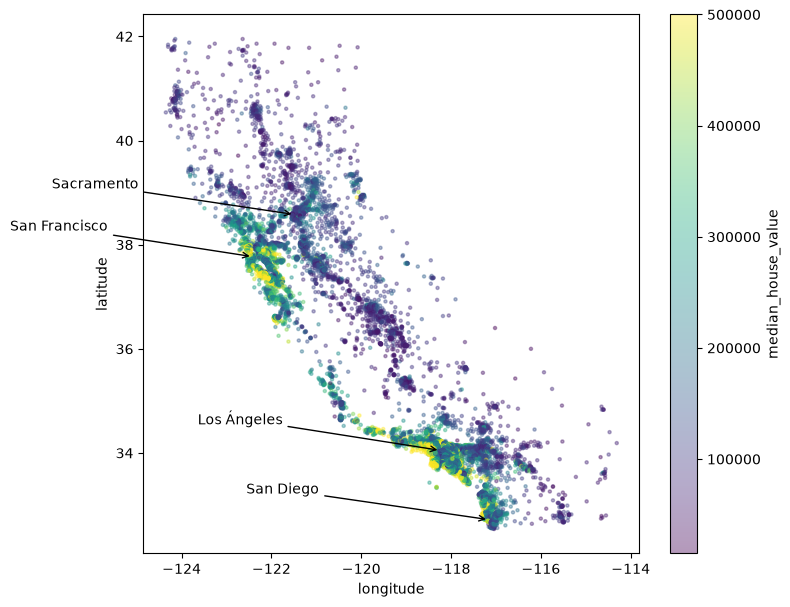

In [36]:
#  - Versión 1.
#  plt.scatter(df_limpio['longitude'], df_limpio['latitude'],
#             c=df_limpio['median_house_value'], s=5, alpha=0.4)
# plt.colorbar(label='median_house_value')
# plt.xlabel('longitude')
# plt.ylabel('latitude')
# plt.show()

plt.figure(figsize=(8, 7))
plt.scatter(df_limpio['longitude'], df_limpio['latitude'],
            c=df_limpio['median_house_value'], s=5, alpha=0.4)
plt.colorbar(label='median_house_value')

ciudades = {
    'San Francisco': (-122.42, 37.77),
    'Sacramento': (-121.49, 38.58),
    'Los Ángeles': (-118.24, 34.05),
    'San Diego': (-117.16, 32.72),
}

for nombre, (lon, lat) in ciudades.items():
    plt.annotate(nombre, xy=(lon, lat), xytext=(lon - 5.4, lat + 0.5),
                 arrowprops=dict(arrowstyle='->'))

plt.xlabel('longitude')
plt.ylabel('latitude')
plt.show()

El mapa dibuja la forma de California, y los precios más altos (en amarillo) se agrupan alrededor de San Francisco, Los Ángeles y San Diego. Las zonas de la costa norte, sin una ciudad grande cerca, tienen precios bajos, y Sacramento, una ciudad grande que no está en la costa, tampoco destaca como cara. Esto explica por qué `latitude` y `longitude` tienen una correlación casi nula con el precio: la relación no es una línea recta, sino concentraciones en lugares concretos.

Los datos sugieren que la combinación de ciudad grande y costa se asocia con las zonas más caras. El dataset no tiene una columna de ciudad, así que no se puede medir cuánto pesa cada factor por separado.

### Relaciones entre variables

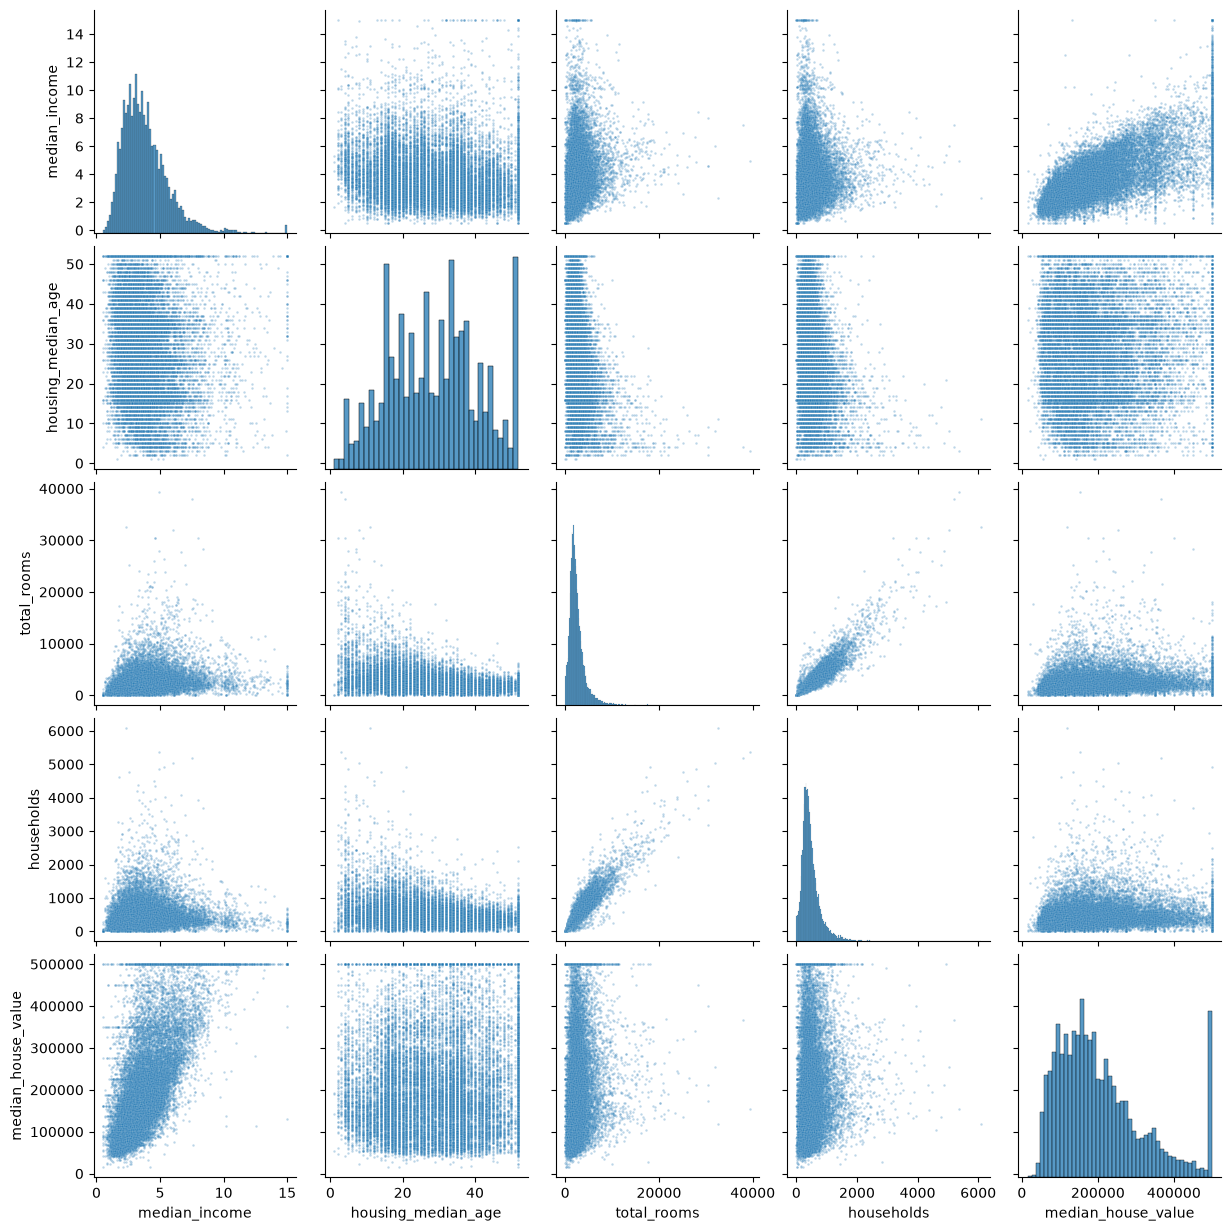

In [37]:
columnas_pair = ['median_income', 'housing_median_age', 'total_rooms',
                 'households', 'median_house_value']

sns.pairplot(df_limpio[columnas_pair], plot_kws={'s': 3, 'alpha': 0.3})
plt.show()

In [38]:
(df_limpio['housing_median_age'] == 52).sum()

np.int64(1265)

In [39]:
df_limpio['housing_median_age'].value_counts().head()

housing_median_age
52.0    1265
36.0     856
35.0     818
16.0     762
17.0     694
Name: count, dtype: int64

En el pairplot, `median_income` contra `median_house_value` forma una nube que sube de izquierda a derecha, con bastante dispersión, y coincide con la correlación de 0,69. Se ve también una línea horizontal en 500.001, que es el tope de precio: a ese valor llegan zonas con ingresos muy distintos.
`housing_median_age` contra el precio no muestra una dirección clara, lo que coincide con su correlación débil (0,11), y las franjas verticales aparecen porque la edad toma valores enteros. `total_rooms` y `households` están muy relacionadas entre sí, por el tamaño de la zona, y ambas poco relacionadas con el precio.

El pairplot también muestra una columna de puntos pegada a 52 en `housing_median_age`. Hay 1.265 zonas con esa edad (6,2%), muy por encima de la siguiente edad más frecuente (36, con 856), lo que apunta a un tope en 52, que significaría "52 años o más".

## Conclusiones

**¿Qué hace caras a las casas en California?** 
Con los datos de este censo de 1990, que describen zonas y no casas individuales, lo que más parece asociarse con precios altos es:

- **Los ingresos de la zona:** `median_income` es la variable más relacionada con el precio (correlación de r = 0,69, o r = 0,64 sin las zonas del tope).
- **La ubicación:** las zonas más caras se agrupan alrededor de San Francisco, Los Ángeles y San Diego, es decir, donde coinciden ciudad grande y costa. Las zonas del interior (`INLAND`) tienen los precios más bajos, mediana de 108.700 contra 215.000 a 233.800 en las otras categorías cercanas al mar, aunque hay una cola de zonas caras para su categoría. Sin contar a `ISLAND`, que tiene una mediana de 414.700.

**Lo que casi no se relaciona con el precio:** `total_rooms`, `total_bedrooms`, `population`, `households` y `housing_median_age`, todas con correlaciones débiles.

**Limitaciones:**
- Tres columnas parecen tener un tope (`median_house_value` en 500.001, `housing_median_age` en 52 y `median_income` en 15,0001), así que no se puede saber cuánto valen realmente esas zonas.
- Son asociaciones, no causas: el dataset no tiene una columna de ciudad, por lo que no se puede medir cuánto pesa cada factor por separado.
- Se eliminaron 207 zonas con `total_bedrooms` nulo (cerca del 1%) sin que se encontrara ningún patrón que las distinguiera.
- `ISLAND` tiene solo 5 zonas, por lo que sus resultados son poco firmes.